<h1 style="color:#161E54; text-align:center;">
Credit Card Risk Analysis
</h1>
<h3 style="color:#359FA0; text-align:center;">
Customer Risk, Payment Behaviour & Credit Utilization
</h3>
<hr style="border:2px solid #359FA0;">

<h2 style="color:#244A73;">1. Import Libraries</h2>

In [2]:
# Import libraries

import pandas as pd
import numpy as np
import pyodbc
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine
from urllib.parse import quote_plus

# Display settings

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", None)

# Visualization settings

sns.set_style("whitegrid")
sns.set_palette("muted")

<h2 style="color:#244A73;">2. SQL Server Connection</h2>

In [3]:
# Connect to SQL Server

server = r"localhost\SQLEXPRESS"
database = "CreditCardRiskDB"

connection_string = (
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={server};"
    f"DATABASE={database};"
    "Trusted_Connection=yes;"
)

connection = pyodbc.connect(connection_string)

print("SQL Server connected successfully.")

SQL Server connected successfully.


<h2 style="color:#244A73;">3. Load Data from SQL Server</h2>

In [4]:
# Load tables into DataFrames

cust = pd.read_sql("SELECT * FROM Cust", connection)
acct = pd.read_sql("SELECT * FROM Acct", connection)
prod = pd.read_sql("SELECT * FROM Prod", connection)

print("Customer Data:", cust.shape)
print("Account Data:", acct.shape)
print("Product Data:", prod.shape)

C:\Users\AISHWARYA\AppData\Local\Temp\ipykernel_9260\3257102395.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  cust = pd.read_sql("SELECT * FROM Cust", connection)
C:\Users\AISHWARYA\AppData\Local\Temp\ipykernel_9260\3257102395.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  acct = pd.read_sql("SELECT * FROM Acct", connection)


Customer Data: (2500, 17)
Account Data: (48000, 21)
Product Data: (5, 5)


C:\Users\AISHWARYA\AppData\Local\Temp\ipykernel_9260\3257102395.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  prod = pd.read_sql("SELECT * FROM Prod", connection)


<h2 style="color:#244A73;">4. Data Overview</h2>

In [5]:
# Preview each dataset

display(cust.head())
display(acct.head())
display(prod.head())

,Customer_ID,First_Name,Last_Name,DOB,Gender,Marital_Status,State,City,Occupation,Annual_Income,Employment_Years,Credit_Score,Customer_Since,Age,Credit_Segment,Age_Segment,Salary_Segment
0,C00001,Karan,Iyer,1975-08-16,Female,Single,Tamil Nadu,Chennai,Student,2047205.0,1.0,739.0,2024-09-01,51.0,700-800,46-55,Premium
1,C00002,Amit,Gupta,1961-07-10,Male,Single,Tamil Nadu,Coimbatore,Business,899047.0,1.0,722.0,2022-04-01,65.0,700-800,55+,Medium
2,C00003,Priya,Verma,1993-11-12,Female,Married,Telangana,Warangal,Student,1335998.0,1.0,596.0,2025-04-01,33.0,<600,26-35,High
3,C00004,Neha,Iyer,1989-10-20,Male,Single,Maharashtra,Mumbai,Government,1796449.0,11.0,761.0,2018-06-01,37.0,700-800,36-45,High
4,C00005,Sneha,Kumar,1969-10-28,Male,Single,Karnataka,Bengaluru,Government,2390354.0,34.0,893.0,2023-06-01,57.0,800>,55+,Premium


,Account_ID,Customer_ID,Product_ID,Account_Open_Date,Statement_Date,Credit_Limit,Outstanding_Balance,Minimum_Due,Amount_Paid,Due_Date,Payment_Date,DPD,Delinquency_Bucket,Payment_Status,Payment_Behaviour,Customer_Segment,MOB,Utilization_Rate,Utilization_Bucket,Chargeoff_Flag,Prev_Month_DPD
0,A002068,C01620,P004,2025-07-01,2025-07-01,300000.0,107973.00,5725.93,6458.86,2025-07-21,2025-08-05,15,1-30,PAID,Above Minimum Due,Revolver,1,35.99%,30-50%,False,NaN
1,A002068,C01620,P004,2025-07-01,2025-07-31,300000.0,109763.14,7031.56,25791.66,2025-08-20,2025-08-25,5,1-30,PAID,Above Minimum Due,Revolver,1,36.59%,30-50%,False,1-30
2,A002068,C01620,P004,2025-07-01,2025-08-30,300000.0,80173.48,4564.00,22709.68,2025-09-19,2025-09-19,0,Current,PAID,Above Minimum Due,Revolver,2,26.72%,10-30%,False,1-30
3,A002068,C01620,P004,2025-07-01,2025-09-29,300000.0,54660.80,4383.59,3655.08,2025-10-19,2025-10-19,0,Current,PAID,Below Minimum Due,Delinquent,3,18.22%,10-30%,False,Current
4,A002068,C01620,P004,2025-07-01,2025-10-29,300000.0,52609.72,2348.69,3571.21,2025-11-18,2025-12-03,15,1-30,PAID,Above Minimum Due,Revolver,4,17.54%,10-30%,False,Current


,Product_ID,Card_Type,Interest_Rate,Annual_Fee,Rewards_Type
0,P001,Classic Card,32.0,499.0,Cashback
1,P002,Gold Card,34.0,999.0,Reward Points
2,P003,Platinum Card,36.0,1999.0,Travel
3,P004,Business Card,30.0,1499.0,Air Miles
4,P005,Student Card,28.0,299.0,Cashback


<h2 style="color:#244A73;">5. Data Quality Checks</h2>

In [6]:
# Check data types, missing values, and duplicates

for name, df in {
    "Customers": cust,
    "Accounts": acct,
    "Products": prod
}.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:")
    print(df.isnull().sum())
    print("\nData types:")
    print(df.dtypes)


Customers
Shape: (2500, 17)
Duplicate rows: 0
Missing values:
Customer_ID          0
First_Name           0
Last_Name            0
DOB                 53
Gender               0
Marital_Status       0
State                0
City                 0
Occupation           0
Annual_Income        0
Employment_Years     0
Credit_Score         0
Customer_Since       0
Age                 53
Credit_Segment       0
Age_Segment          0
Salary_Segment       0
dtype: int64

Data types:
Customer_ID                    str
First_Name                     str
Last_Name                      str
DOB                 datetime64[us]
Gender                         str
Marital_Status                 str
State                          str
City                           str
Occupation                     str
Annual_Income              float64
Employment_Years           float64
Credit_Score               float64
Customer_Since      datetime64[us]
Age                        float64
Credit_Segment                

<h2 style="color:#161E54;">05 | Customer Feature Engineering</h2>
<p style="color:#359FA0;">Age, Credit Score, Income and Employment</p>
<hr style="border:1px solid #359FA0;">

In [7]:
# Calculate Age

cust["DOB"] = pd.to_datetime(cust["DOB"])
cust["Age"] = (pd.Timestamp.today() - cust["DOB"]).dt.days // 365

# Credit Score Segment

cust["Credit_Segment"] = np.select(
    [
        cust["Credit_Score"] < 600,
        cust["Credit_Score"] < 700,
        cust["Credit_Score"] < 800
    ],
    ["<600", "600-700", "700-800"],
    default="800+"
)

# Age Segment

cust["Age_Segment"] = pd.cut(
    cust["Age"],
    bins=[0, 25, 35, 45, 55, np.inf],
    labels=["18-25", "26-35", "36-45", "46-55", "55+"]
)

# Salary Segment

cust["Salary_Segment"] = np.select(
    [
        cust["Annual_Income"] < 500000,
        cust["Annual_Income"] < 1000000,
        cust["Annual_Income"] < 2000000
    ],
    ["Low", "Medium", "High"],
    default="Premium"
)

# Employment Years for Students

cust.loc[cust["Occupation"] == "Student", "Employment_Years"] = 1

display(cust.head())

,Customer_ID,First_Name,Last_Name,DOB,Gender,Marital_Status,State,City,Occupation,Annual_Income,Employment_Years,Credit_Score,Customer_Since,Age,Credit_Segment,Age_Segment,Salary_Segment
0,C00001,Karan,Iyer,1975-08-16,Female,Single,Tamil Nadu,Chennai,Student,2047205.0,1.0,739.0,2024-09-01,51.0,700-800,46-55,Premium
1,C00002,Amit,Gupta,1961-07-10,Male,Single,Tamil Nadu,Coimbatore,Business,899047.0,1.0,722.0,2022-04-01,65.0,700-800,55+,Medium
2,C00003,Priya,Verma,1993-11-12,Female,Married,Telangana,Warangal,Student,1335998.0,1.0,596.0,2025-04-01,32.0,<600,26-35,High
3,C00004,Neha,Iyer,1989-10-20,Male,Single,Maharashtra,Mumbai,Government,1796449.0,11.0,761.0,2018-06-01,37.0,700-800,36-45,High
4,C00005,Sneha,Kumar,1969-10-28,Male,Single,Karnataka,Bengaluru,Government,2390354.0,34.0,893.0,2023-06-01,57.0,800+,55+,Premium


,min,max,mean
Occupation,,,
Business,21.0,66.0,44.241379
Government,21.0,66.0,42.558140
Salaried,21.0,66.0,44.674180
Self Employed,21.0,66.0,44.146694
Student,21.0,66.0,43.514870


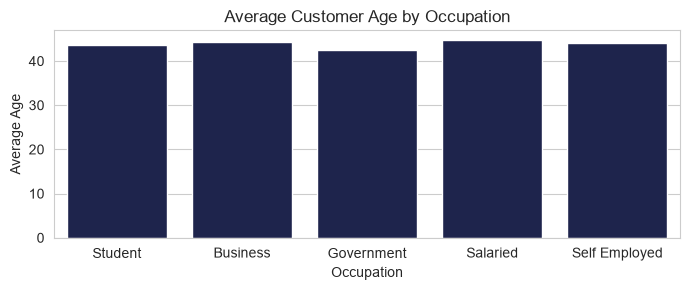

In [22]:

# Age Analysis by Occupation

age_analysis = cust.groupby("Occupation")["Age"].agg(["min", "max", "mean"])
display(age_analysis)


# Visualization

plt.figure(figsize=(7, 3))
sns.barplot(
    data=cust,
    x="Occupation",
    y="Age",
    color="#161E54",
    errorbar=None
)

plt.title("Average Customer Age by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Average Age")
plt.tight_layout()
plt.show()


<h3 style="color:#161E54;">1. Age Analysis by Occupation</h3>

- <span style="color:#359FA0;">Salaried customers</span> have the highest average age at 44.67 years, followed by Business customers at 44.24 years.
- <span style="color:#F16D34;">Government employees</span> have the lowest average age at 42.56 years, showing a difference of 2.11 years compared with Salaried customers.
- All occupation groups share the same age range of 21–66 years, indicating similar age coverage across professions.

<h3 style="color:#161E54;">2. Business Insight</h3>

Average customer age varies only slightly across occupations. This suggests that occupation-based age differences are limited within the current customer base. Further comparison of credit scores, delinquency, and charge-off rates by occupation would help determine whether these groups differ meaningfully in credit risk.


<h2 style="color:#161E54;">06 | Account Feature Engineering</h2>
<p style="color:#359FA0;">DPD, Delinquency, Payment Behaviour, MOB and Credit Utilization</p>
<hr style="border:1px solid #359FA0;">

In [9]:
# Convert date columns

date_columns = ["Payment_Date", "Due_Date", "Account_Open_Date", "Statement_Date"]

for column in date_columns:
    acct[column] = pd.to_datetime(acct[column], errors="coerce")

# Calculate Days Past Due

acct["DPD"] = np.where(
    acct["Payment_Date"].isna(),
    (pd.Timestamp.today().normalize() - acct["Due_Date"]).dt.days,
    np.where(
        acct["Payment_Date"] <= acct["Due_Date"],
        0,
        (acct["Payment_Date"] - acct["Due_Date"]).dt.days
    )
)

acct.loc[acct["Due_Date"].isna(), "DPD"] = np.nan

# Delinquency Bucket

acct["Delinquency_Bucket"] = np.select(
    [
        acct["DPD"] == 0,
        acct["DPD"].between(1, 30),
        acct["DPD"].between(31, 60),
        acct["DPD"].between(61, 90),
        acct["DPD"] > 90
    ],
    ["Current", "1-30", "31-60", "61-90", "90+"],
    default="Unknown"
)

display(acct[["Account_ID", "DPD", "Delinquency_Bucket"]].head())

,Account_ID,DPD,Delinquency_Bucket
0,A002068,15.0,1-30
1,A002068,5.0,1-30
2,A002068,0.0,Current
3,A002068,0.0,Current
4,A002068,15.0,1-30


In [10]:
# Convert payment columns to numeric

payment_columns = ["Amount_Paid", "Minimum_Due", "Outstanding_Balance", "Credit_Limit"]

for column in payment_columns:
    acct[column] = pd.to_numeric(acct[column], errors="coerce")

# Payment Status

acct["Payment_Status"] = np.where(
    acct["Amount_Paid"].isna(), "NOT PAID", "PAID"
)

# Payment Behaviour

acct["Payment_Behaviour"] = np.select(
    [
        acct["Amount_Paid"].isna() | (acct["Amount_Paid"] == 0),
        acct["Amount_Paid"] < acct["Minimum_Due"],
        acct["Amount_Paid"] == acct["Minimum_Due"],
        (acct["Amount_Paid"] > acct["Minimum_Due"]) &
        (acct["Amount_Paid"] < acct["Outstanding_Balance"]),
        acct["Amount_Paid"] >= acct["Outstanding_Balance"]
    ],
    [
        "No Payment",
        "Below Minimum Due",
        "Minimum Due Paid",
        "Above Minimum Due",
        "Full Payment"
    ],
    default="Unclassified"
)

# Customer Repayment Segment

acct["Customer_Segment"] = np.select(
    [
        acct["Amount_Paid"] >= acct["Outstanding_Balance"],
        (acct["Amount_Paid"] >= acct["Minimum_Due"]) &
        (acct["Amount_Paid"] < acct["Outstanding_Balance"]),
        (acct["Amount_Paid"] > 0) &
        (acct["Amount_Paid"] < acct["Minimum_Due"]),
        acct["Amount_Paid"].isna() | (acct["Amount_Paid"] == 0)
    ],
    ["Transactor", "Revolver", "Delinquent", "No Payment"],
    default="Unclassified"
)

display(acct[["Account_ID", "Payment_Status", "Payment_Behaviour", "Customer_Segment"]].head())

,Account_ID,Payment_Status,Payment_Behaviour,Customer_Segment
0,A002068,PAID,Above Minimum Due,Revolver
1,A002068,PAID,Above Minimum Due,Revolver
2,A002068,PAID,Above Minimum Due,Revolver
3,A002068,PAID,Below Minimum Due,Delinquent
4,A002068,PAID,Above Minimum Due,Revolver


In [11]:
# Months on Book

acct["MOB"] = (
    (acct["Statement_Date"].dt.year - acct["Account_Open_Date"].dt.year) * 12
    + acct["Statement_Date"].dt.month
    - acct["Account_Open_Date"].dt.month
    + 1
)

# Utilization Rate

acct["Utilization_Rate"] = (
    acct["Outstanding_Balance"] / acct["Credit_Limit"].replace(0, np.nan)
)

# Utilization Bucket

acct["Utilization_Bucket"] = np.select(
    [
        acct["Outstanding_Balance"] == 0,
        acct["Utilization_Rate"] <= 0.10,
        acct["Utilization_Rate"] <= 0.30,
        acct["Utilization_Rate"] <= 0.50,
        acct["Utilization_Rate"] <= 0.75,
        acct["Utilization_Rate"] <= 0.90,
        acct["Utilization_Rate"] > 0.90
    ],
    ["No Usage", "0-10%", "10-30%", "30-50%", "50-75%", "75-90%", ">90%"],
    default="Unknown"
)

# Charge-off Flag

acct["Chargeoff_Flag"] = np.where(acct["DPD"] > 90, 1, 0)

# Previous Statement Delinquency

acct = acct.sort_values(["Account_ID", "Statement_Date"])

acct["Prev_Month_DPD"] = (
    acct.groupby("Account_ID")["Delinquency_Bucket"].shift(1)
)

display(acct.head())

,Account_ID,Customer_ID,Product_ID,Account_Open_Date,Statement_Date,Credit_Limit,Outstanding_Balance,Minimum_Due,Amount_Paid,Due_Date,Payment_Date,DPD,Delinquency_Bucket,Payment_Status,Payment_Behaviour,Customer_Segment,MOB,Utilization_Rate,Utilization_Bucket,Chargeoff_Flag,Prev_Month_DPD
1908,A000001,C00186,P001,2025-08-01,2025-08-01,150000.0,50950.00,3485.18,15700.36,2025-08-21,2025-08-26,5.0,1-30,PAID,Above Minimum Due,Revolver,1,0.339667,30-50%,0,NaN
1909,A000001,C00186,P001,2025-08-01,2025-08-31,150000.0,34972.64,1497.06,3000.82,2025-09-20,2025-09-20,0.0,Current,PAID,Above Minimum Due,Revolver,1,0.233151,10-30%,0,1-30
1910,A000001,C00186,P001,2025-08-01,2025-09-30,150000.0,31820.82,2532.41,308.68,2025-10-20,2025-11-04,15.0,1-30,PAID,Below Minimum Due,Delinquent,2,0.212139,10-30%,0,Current
1911,A000001,C00186,P001,2025-08-01,2025-10-30,150000.0,27038.14,1345.75,8046.52,2025-11-19,2025-11-19,0.0,Current,PAID,Above Minimum Due,Revolver,3,0.180254,10-30%,0,1-30
1912,A000001,C00186,P001,2025-08-01,2025-11-29,150000.0,18179.62,987.26,3001.76,2025-12-19,2025-12-19,0.0,Current,PAID,Above Minimum Due,Revolver,4,0.121197,10-30%,0,Current


<h2 style="color:#161E54;">07 | Customer Risk Analysis</h2>
<p style="color:#359FA0;">Credit score, age and income distribution</p>
<hr style="border:1px solid #359FA0;">

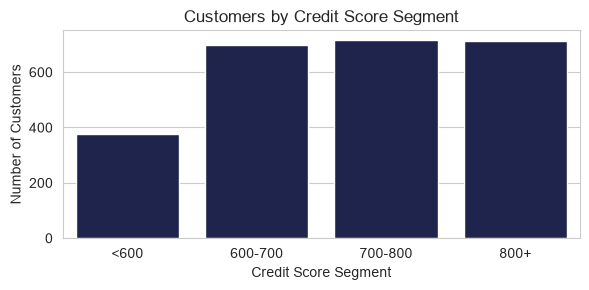

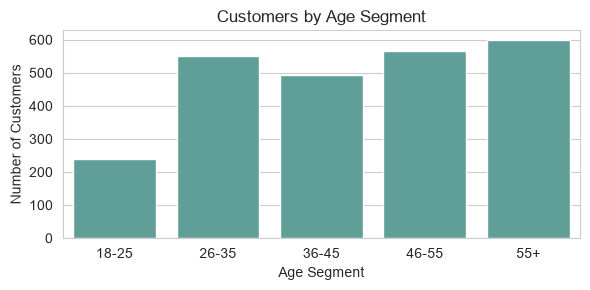

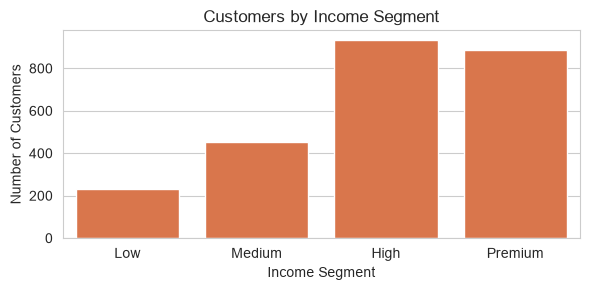

In [23]:
# Credit Score Segment

plt.figure(figsize=(6, 3))
sns.countplot(
    data=cust, x="Credit_Segment",
    order=["<600", "600-700", "700-800", "800+"],
    color="#161E54"
)

plt.title("Customers by Credit Score Segment")
plt.xlabel("Credit Score Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# Age Segment

plt.figure(figsize=(6, 3))
sns.countplot(
    data=cust, x="Age_Segment",
    color="#55A9A0"
)

plt.title("Customers by Age Segment")
plt.xlabel("Age Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# Salary Segment

plt.figure(figsize=(6, 3))
sns.countplot(
    data=cust, x="Salary_Segment",
    order=["Low", "Medium", "High", "Premium"],
    color="#F16D34"
)

plt.title("Customers by Income Segment")
plt.xlabel("Income Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


<h3 style="color:#161E54;">1. Credit Score Distribution</h3>

- Customers scoring 700–800 account for <span style="color:#359FA0;">28.60%</span>, closely followed by those scoring above 800 at <span style="color:#359FA0;">28.52%</span>.
- Customers with credit scores below 600 represent <span style="color:#F16D34;">15.00%</span> of the customer base and warrant further credit risk analysis.

<h3 style="color:#161E54;">2. Age Distribution</h3>

- Customers aged 46 and above account for <span style="color:#359FA0;">47.53%</span> of the customer base.
- Customers aged 18–25 represent only <span style="color:#F16D34;">9.81%</span>, making them the least represented age group.

<h3 style="color:#161E54;">3. Income Distribution</h3>

- High- and premium-income customers account for <span style="color:#359FA0;">72.68%</span> of the customer base.
- Low-income customers represent just <span style="color:#F16D34;">9.20%</span>.

<h3 style="color:#161E54;">4. Overall Business Insight</h3>

The portfolio is concentrated among higher-income and mature customers. Further analysis of delinquency and charge-off rates across credit score, age, and income segments will help identify the customer groups contributing most to credit risk.


<h2 style="color:#161E54;">08 | Payment Behaviour Analysis</h2>
<p style="color:#359FA0;">Payment status and repayment patterns</p>
<hr style="border:1px solid #359FA0;">

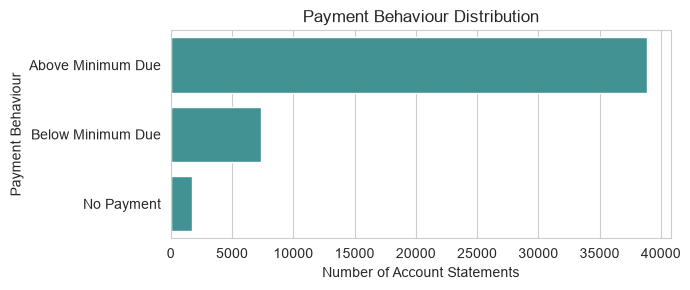

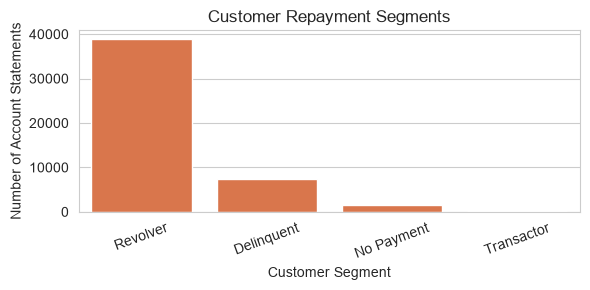

In [14]:
# Payment Behaviour Distribution

plt.figure(figsize=(7, 3))
sns.countplot(
    data=acct,
    y="Payment_Behaviour",
    order=acct["Payment_Behaviour"].value_counts().index,
    color="#359FA0"
)

plt.title("Payment Behaviour Distribution")
plt.xlabel("Number of Account Statements")
plt.ylabel("Payment Behaviour")
plt.tight_layout()
plt.show()


# Customer Repayment Segments

plt.figure(figsize=(6, 3))
sns.countplot(
    data=acct,
    x="Customer_Segment",
    order=acct["Customer_Segment"].value_counts().index,
    color="#F16D34"
)

plt.title("Customer Repayment Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Account Statements")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

<h2 style="color:#161E54;">09 | Delinquency Analysis</h2>
<p style="color:#359FA0;">Days Past Due and delinquency bucket distribution</p>
<hr style="border:1px solid #359FA0;">

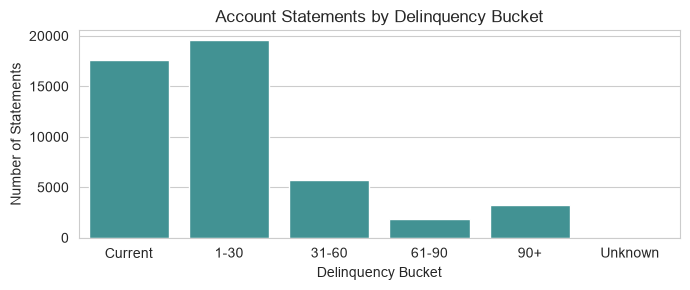

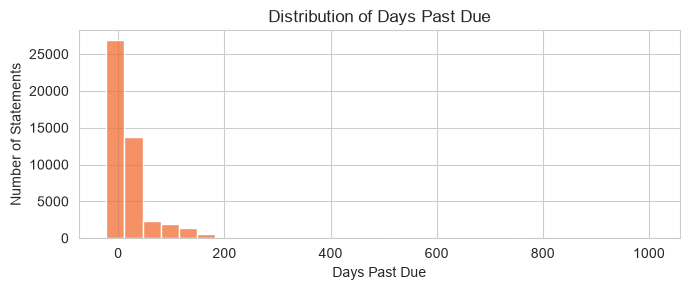

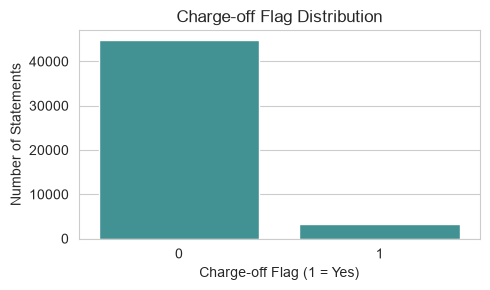

In [16]:
# Delinquency Bucket Distribution

bucket_order = ["Current", "1-30", "31-60", "61-90", "90+", "Unknown"]

plt.figure(figsize=(7, 3))
sns.countplot(
    data=acct,
    x="Delinquency_Bucket",
    order=bucket_order,
    color="#359FA0"
)

plt.title("Account Statements by Delinquency Bucket")
plt.xlabel("Delinquency Bucket")
plt.ylabel("Number of Statements")
plt.tight_layout()
plt.show()


# DPD Distribution

plt.figure(figsize=(7, 3))
sns.histplot(
    data=acct,
    x="DPD",
    bins=30,
    color="#F16D34"
)

plt.title("Distribution of Days Past Due")
plt.xlabel("Days Past Due")
plt.ylabel("Number of Statements")
plt.tight_layout()
plt.show()


# Charge-off Flag

plt.figure(figsize=(5, 3))
sns.countplot(
    data=acct,
    x="Chargeoff_Flag",
    color="#359FA0"
)

plt.title("Charge-off Flag Distribution")
plt.xlabel("Charge-off Flag (1 = Yes)")
plt.ylabel("Number of Statements")
plt.tight_layout()
plt.show()


<h3 style="color:#161E54;">1. Payment Behaviour Distribution</h3>

- <span style="color:#359FA0;">80.99%</span> of account statements fall under Above Minimum Due, indicating that most recorded payments are above the minimum due threshold.
- <span style="color:#F16D34;">15.39%</span> fall under Below Minimum Due, highlighting an area for further investigation into repayment shortfalls.
- Only 3.63% are classified as No Payment, representing a smaller group that may require closer monitoring for missed payments.

<h3 style="color:#161E54;">2. Customer Repayment Segments</h3>

- Revolvers account for 80.99% of account statements, making them the dominant repayment segment.
- Delinquent accounts represent 15.39%, indicating a notable share that warrants further analysis of overdue payments.
- Transactors account for only 0.60%, making them the smallest segment in the portfolio.

<h3 style="color:#161E54;">3. Overall Business Insight</h3>

The account portfolio is heavily concentrated among Revolvers, while Delinquent accounts represent a meaningful share of recorded statements. Further analysis of outstanding balances, delinquency buckets, and charge-off rates can help assess the financial risk associated with these repayment patterns.


<h2 style="color:#161E54;">10 | Credit Utilization Analysis</h2>
<p style="color:#359FA0;">Utilization buckets and outstanding balance patterns</p>
<hr style="border:1px solid #359FA0;">

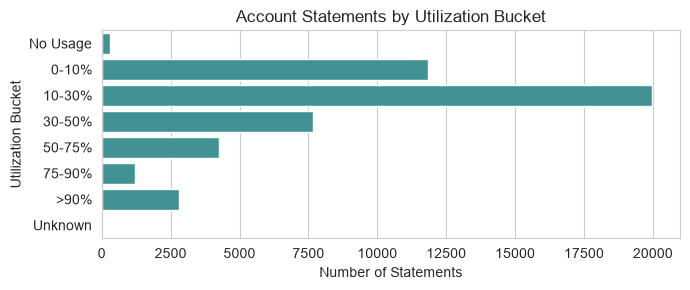

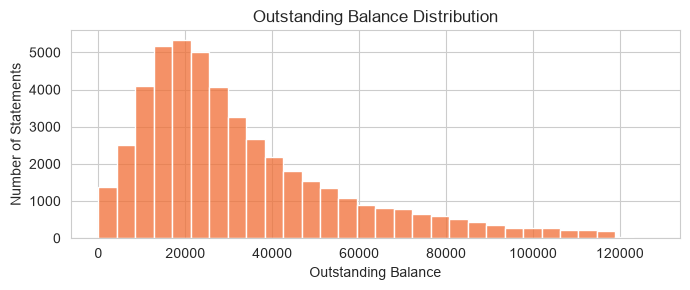

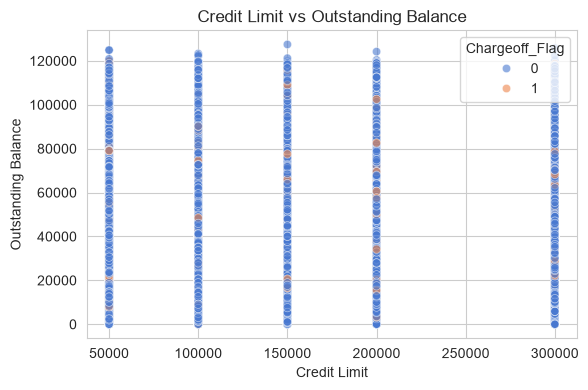

In [20]:
# Utilization Bucket Distribution

utilization_order = [
    "No Usage", "0-10%", "10-30%", "30-50%",
    "50-75%", "75-90%", ">90%", "Unknown"
]

plt.figure(figsize=(7, 3))
sns.countplot(
    data=acct,
    y="Utilization_Bucket",
    order=utilization_order,
    color="#359FA0"
)

plt.title("Account Statements by Utilization Bucket")
plt.xlabel("Number of Statements")
plt.ylabel("Utilization Bucket")
plt.tight_layout()
plt.show()


# Outstanding Balance Distribution

plt.figure(figsize=(7, 3))
sns.histplot(
    data=acct,
    x="Outstanding_Balance",
    bins=30,
    color="#F16D34"
)

plt.title("Outstanding Balance Distribution")
plt.xlabel("Outstanding Balance")
plt.ylabel("Number of Statements")
plt.tight_layout()
plt.show()


# Credit Limit vs Outstanding Balance

plt.figure(figsize=(6, 4))
sns.scatterplot(
    data=acct,
    x="Credit_Limit",
    y="Outstanding_Balance",
    hue="Chargeoff_Flag",
    alpha=0.6
)

plt.title("Credit Limit vs Outstanding Balance")
plt.xlabel("Credit Limit")
plt.ylabel("Outstanding Balance")
plt.tight_layout()
plt.show()


<h3 style="color:#161E54;">1. Credit Utilization Distribution</h3>

- <span style="color:#359FA0;">41.64%</span> of account statements fall within the 10–30% utilization range, making it the most common category.
- A further 24.63% fall within the 0–10% range, while 15.95% fall within 30–50%.
- Only 8.32% of statements fall within the 75–90% and above-90% utilization ranges combined with the 75–90% category? 
- High utilization above 90% accounts for 5.82%, identifying a segment worth monitoring for potential credit exposure.

<h3 style="color:#161E54;">2. Outstanding Balance Distribution</h3>

- The average outstanding balance is 32,813.54, compared with a median of 25,940.34, suggesting that higher balances may be pulling the average upward.
- Balances range from 0 to 127,453, indicating substantial variation in outstanding amounts across account statements.
- The middle 50% of balances lie between 16,080.72 and 43,070.54.

<h3 style="color:#161E54;">3. Credit Limit vs Outstanding Balance by Charge-off Status</h3>

- Accounts without a charge-off have an average outstanding balance of 32,776.34, compared with 33,324.31 for charge-off accounts.
- The average credit limit is slightly lower for charge-off accounts (155,108.93) than for accounts without a charge-off (157,097.52).
- The difference in average outstanding balances is relatively small, so these figures alone do not establish a strong relationship between balance size and charge-off status.

<h3 style="color:#161E54;">4. Overall Business Insight</h3>

Most account statements show relatively low-to-moderate credit utilization, although 5.82% exceed 90% utilization. Charge-off accounts have slightly higher average outstanding balances and slightly lower average credit limits. Further analysis of charge-off rates by utilization bucket is needed to determine whether high utilization is associated with increased credit risk.


<h2 style="color:#161E54;">11 | Product Analysis</h2>
<p style="color:#359FA0;">Product distribution and account exposure</p>
<hr style="border:1px solid #359FA0;">

In [29]:
# Inspect available product columns

display(prod.head())
print("Product columns:", prod.columns.tolist())

,Product_ID,Card_Type,Interest_Rate,Annual_Fee,Rewards_Type
0,P001,Classic Card,32.0,499.0,Cashback
1,P002,Gold Card,34.0,999.0,Reward Points
2,P003,Platinum Card,36.0,1999.0,Travel
3,P004,Business Card,30.0,1499.0,Air Miles
4,P005,Student Card,28.0,299.0,Cashback


Product columns: ['Product_ID', 'Card_Type', 'Interest_Rate', 'Annual_Fee', 'Rewards_Type']



<h3 style="color:#161E54;">1. Card Type Distribution</h3>

- All five card types — Classic, Gold, Platinum, Business, and Student — represent <span style="color:#359FA0;">20% each</span> of the product portfolio.
- The equal distribution indicates that the product dataset provides balanced representation across card categories.

<h3 style="color:#161E54;">2. Interest Rate Analysis</h3>

- Interest rates range from <span style="color:#F16D34;">28% to 36%</span>, with an average of 32%.
- Platinum Card has the highest interest rate at 36%, while Student Card has the lowest at 28%.
- Business and Classic Cards have interest rates of 30% and 32%, respectively, while Gold Card stands at 34%.

<h3 style="color:#161E54;">3. Annual Fee Analysis</h3>

- Annual fees range from 299 to 1,999, with an average fee of 1,059.
- Platinum Card has the highest annual fee at 1,999, while Student Card has the lowest at 299.
- The fee structure varies considerably across card types, reflecting different product pricing tiers.

<h3 style="color:#161E54;">4. Rewards Type Analysis</h3>

- Cashback is the most common rewards type, accounting for <span style="color:#359FA0;">40%</span> of products.
- Reward Points, Travel, and Air Miles each account for 20% of the portfolio.
- Cashback has the widest representation among the available rewards options.

<h3 style="color:#161E54;">5. Overall Business Insight</h3>

The product portfolio offers five card categories with distinct pricing and interest-rate structures. Platinum Card occupies the highest-fee and highest-interest position, whereas Student Card has the lowest fee and interest rate. Cashback is the most widely represented rewards option. These differences provide a basis for comparing product positioning, but customer-level data would be needed to assess actual product popularity, profitability, and credit risk.


<h2 style="color:#161E54;">12 | Key Findings</h2>
<p style="color:#359FA0;">Portfolio metrics and risk indicators</p>
<hr style="border:1px solid #359FA0;">

In [19]:
# Portfolio summary

portfolio_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Total Account Statements",
        "Total Accounts",
        "Total Products",
        "Unpaid Statements",
        "Statements with DPD above 90",
        "Charge-off Statements",
        "Average Credit Utilization"
    ],
    "Value": [
        cust["Customer_ID"].nunique(),
        len(acct),
        acct["Account_ID"].nunique(),
        prod["Product_ID"].nunique(),
        (acct["Payment_Status"] == "NOT PAID").sum(),
        (acct["DPD"] > 90).sum(),
        acct["Chargeoff_Flag"].sum(),
        acct["Utilization_Rate"].mean()
    ]
})

display(portfolio_summary)

,Metric,Value
0,Total Customers,2500.000000
1,Total Account Statements,48000.000000
2,Total Accounts,4000.000000
3,Total Products,5.000000
4,Unpaid Statements,1453.000000
5,Statements with DPD above 90,3259.000000
6,Charge-off Statements,3259.000000
7,Average Credit Utilization,0.304065



<h3 style="color:#161E54;">1. Portfolio Overview</h3>

- The portfolio covers <span style="color:#359FA0;">2,500 customers</span>, 4,000 accounts, and 5 distinct card products.
- A total of 48,000 account statements are available for analysis, providing a broad view of account-level payment behaviour.

<h3 style="color:#161E54;">2. Payment and Delinquency Risk</h3>

- Out of 48,000 statements, 1,453 are marked as NOT PAID, representing approximately 3.03% of all statements.
- A total of 3,259 statements have Days Past Due (DPD) above 90, accounting for approximately 6.79% of statements.
- The dataset records 3,259 charge-off statements, also approximately 6.79% of the total. The matching counts warrant validation to confirm whether every statement above 90 DPD is associated with a charge-off.

<h3 style="color:#161E54;">3. Credit Utilization</h3>

- Average credit utilization is approximately <span style="color:#F16D34;">30.41%</span>, indicating that around 30% of available credit is used on average, assuming Utilization_Rate is stored as a decimal.

<h3 style="color:#161E54;">4. Overall Business Insight</h3>

The portfolio contains a substantial volume of account-level data across a relatively small number of customers and products. Although the overall average utilization is around 30.41%, the presence of statements exceeding 90 DPD and recorded charge-offs highlights the importance of monitoring delinquency and potential credit losses. Further analysis should compare charge-off rates across utilization buckets, repayment segments, and credit score groups to identify the strongest risk indicators.



<h3 style="color:#161E54;">Final Summary</h3>

This project analyzed customer profiles, credit utilization, repayment behaviour, product features, delinquency, and charge-offs to identify portfolio trends and support data-driven credit risk assessment.



<h2 style="color:#161E54; text-align:center;">Thank You!</h2>

<p style="color:#359FA0; text-align:center;">Credit Card Portfolio & Risk Analytics</p>
